# 05 - 1D CNN
The input is a configurable sequence of consecutive window-level vectors (default length 5). A sequence never crosses a recording or shared split boundary; the last window supplies the target. Scaling is fitted on train rows only.

This notebook requires PyTorch. A small or single-group dataset is reported as insufficient evidence rather than treated as proof of neural-network superiority.

{
  "Accuracy": 0.9784342356509041,
  "Precision": 0.5231481481481481,
  "Recall": 0.5594059405940595,
  "F1": 0.5406698564593302,
  "ConfusionMatrix": [
    [
      8598,
      103
    ],
    [
      89,
      113
    ]
  ],
  "ClassificationReport": {
    "normal": {
      "precision": 0.9897548060320018,
      "recall": 0.9881622801976784,
      "f1-score": 0.9889579020013802,
      "support": 8701.0
    },
    "seizure": {
      "precision": 0.5231481481481481,
      "recall": 0.5594059405940595,
      "f1-score": 0.5406698564593302,
      "support": 202.0
    },
    "accuracy": 0.9784342356509041,
    "macro avg": {
      "precision": 0.756451477090075,
      "recall": 0.7737841103958689,
      "f1-score": 0.7648138792303552,
      "support": 8903.0
    },
    "weighted avg": {
      "precision": 0.9791679763237531,
      "recall": 0.9784342356509041,
      "f1-score": 0.9787867029449392,
      "support": 8903.0
    }
  },
  "PR-AUC": 0.38360647233864187
}


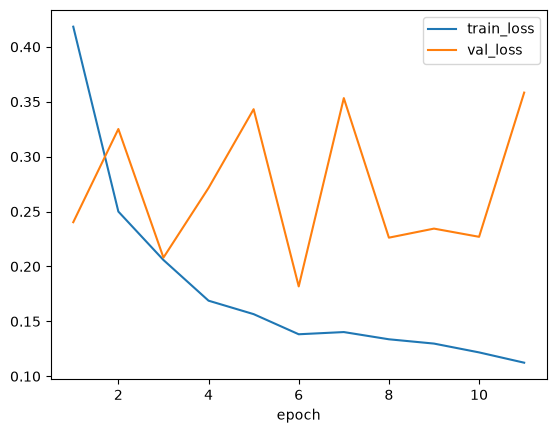

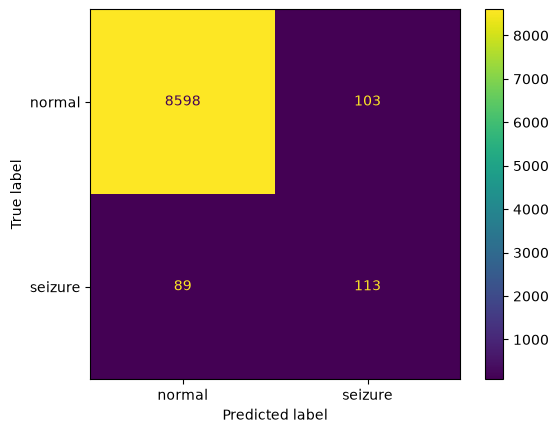

In [1]:
from pathlib import Path
import sys, copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay
try:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
except ImportError as exc:
    raise ImportError('Install requirements.txt to run the CNN notebook; no neural result was produced.') from exc
ROOT=Path.cwd()
if not (ROOT/'eeg_app').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from eeg_app.src.experiments import load_unbalanced_split, balance_sequences, feature_names, make_sequences, evaluate_predictions, experiment_dirs, seed_everything
seed_everything(42); device=torch.device('cuda' if torch.cuda.is_available() else 'cpu'); frame,balance_method=load_unbalanced_split(ROOT); features=feature_names(frame); length=5
train_rows=frame[frame.split.eq('train')]; imputer=SimpleImputer(strategy='median').fit(train_rows[features]); scaler=StandardScaler().fit(imputer.transform(train_rows[features])); scaled=frame.copy(); scaled[features]=scaler.transform(imputer.transform(frame[features])); X,y,meta=make_sequences(scaled,length,features)
if len(X)<30 or meta.split.nunique()<2: print('WARNING: insufficient sequence data for reliable neural training:',X.shape,meta.split.nunique())
mask={name:meta.split.eq(name).to_numpy() for name in ('train','validation','test')}; X_train,y_train=balance_sequences(X[mask['train']],y[mask['train']],balance_method,seed=42); X_val,y_val=X[mask['validation']],y[mask['validation']]; X_test,y_test=X[mask['test']],y[mask['test']]
class CNN1D(nn.Module):
    def __init__(self,n_features):
        super().__init__(); self.net=nn.Sequential(nn.Conv1d(n_features,32,3,padding=1),nn.ReLU(),nn.BatchNorm1d(32),nn.Conv1d(32,16,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool1d(1)); self.head=nn.Linear(16,2)
    def forward(self,x): return self.head(self.net(x.transpose(1,2)).squeeze(-1))
model=CNN1D(len(features)).to(device); counts=np.bincount(y_train,minlength=2); weights=torch.tensor([1.0, float(counts[0]/max(1,counts[1]))],dtype=torch.float32,device=device); loss_fn=nn.CrossEntropyLoss(weight=weights); optimizer=torch.optim.Adam(model.parameters(),lr=1e-3,weight_decay=1e-4)
train_loader=DataLoader(TensorDataset(torch.tensor(X_train),torch.tensor(y_train)),batch_size=64,shuffle=True,generator=torch.Generator().manual_seed(42)); val_loader=DataLoader(TensorDataset(torch.tensor(X_val),torch.tensor(y_val)),batch_size=256)
history=[]; best_state=None; best_f1=-1; patience=0
for epoch in range(30):
    model.train(); train_loss=0.0
    for xb,yb in train_loader:
        optimizer.zero_grad(); loss=loss_fn(model(xb.to(device)),yb.to(device)); loss.backward(); optimizer.step(); train_loss+=float(loss.item())*len(yb)
    model.eval(); val_loss=0.0; val_pred=[]
    with torch.no_grad():
        for xb,yb in val_loader:
            logits=model(xb.to(device)); val_loss+=float(loss_fn(logits,yb.to(device)).item())*len(yb); val_pred.extend(logits.argmax(1).cpu().numpy())
    from sklearn.metrics import f1_score
    val_f1=f1_score(y_val,val_pred,zero_division=0) if len(y_val) else 0.0; history.append({'epoch':epoch+1,'train_loss':train_loss/max(1,len(y_train)),'val_loss':val_loss/max(1,len(y_val)),'val_f1':val_f1})
    if val_f1>best_f1: best_f1=val_f1; best_state=copy.deepcopy(model.state_dict()); patience=0
    else: patience+=1
    if patience>=5: break
if best_state is not None: model.load_state_dict(best_state)
model.eval();
with torch.no_grad(): test_logits=model(torch.tensor(X_test).to(device)); test_pred=test_logits.argmax(1).cpu().numpy(); test_score=torch.softmax(test_logits,1)[:,1].cpu().numpy()
metrics=evaluate_predictions(y_test,test_pred,test_score); dirs=experiment_dirs(ROOT); dirs['models'].mkdir(exist_ok=True); dirs['results'].mkdir(exist_ok=True); torch.save({'state_dict':model.state_dict(),'features':features,'sequence_length':length,'imputer':imputer,'scaler':scaler},dirs['models']/'cnn_1d.pt'); out=meta.loc[mask['test'],['patient_id','recording_id','window_id','start_time','end_time','label']].copy(); out['prediction']=test_pred; out['score']=test_score; out.to_csv(dirs['results']/'cnn_1d_test_predictions.csv',index=False); (dirs['results']/'cnn_1d_test_metrics.json').write_text(json.dumps(metrics,indent=2,default=str),encoding='utf-8'); pd.DataFrame(history).to_csv(dirs['results']/'cnn_1d_training_history.csv',index=False); print(json.dumps(metrics,indent=2)); pd.DataFrame(history).plot(x='epoch',y=['train_loss','val_loss']); plt.show(); ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['normal','seizure']); plt.show()

In [2]:
model.eval()
with torch.no_grad():
    validation_logits = model(torch.tensor(X_val).to(device))
    validation_pred = validation_logits.argmax(1).cpu().numpy()
validation_metrics = evaluate_predictions(y_val, validation_pred)
(dirs['results'] / 'cnn_1d_validation.json').write_text(json.dumps({'F1': validation_metrics['F1'], 'Recall': validation_metrics['Recall']}, indent=2), encoding='utf-8')
print('Saved validation selection metrics:', validation_metrics['F1'], validation_metrics['Recall'])

Saved validation selection metrics: 0.6672879776328052 0.7584745762711864
